In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [8]:
DATA_DIR = Path("data")
if not (DATA_DIR / "diabetes_prediction_dataset.csv").is_file():
    sibling_data_dirs = [
        path.parent / "data"
        for path in Path.cwd().rglob("TH2.ipynb")
        if (path.parent / "data" / "diabetes_prediction_dataset.csv").is_file()
    ]
    if len(sibling_data_dirs) != 1:
        raise FileNotFoundError(
            "Could not uniquely find the data folder beside TH2.ipynb. "
            "Run this notebook from its folder or update DATA_DIR."
        )
    DATA_DIR = sibling_data_dirs[0]

DATA_FILE = DATA_DIR / "diabetes_prediction_dataset.csv"
if not DATA_FILE.is_file():
    raise FileNotFoundError(f"Diabetes dataset not found: {DATA_FILE}")

df = pd.read_csv(DATA_FILE)
target = "diabetes"
numeric_features = [
    "age",
    "hypertension",
    "heart_disease",
    "bmi",
    "HbA1c_level",
    "blood_glucose_level",
]
categorical_features = ["gender", "smoking_history"]
features = numeric_features + categorical_features
required_columns = features + [target]
if missing := set(required_columns) - set(df.columns):
    raise ValueError(f"Dataset is missing columns: {sorted(missing)}")
if df[target].isna().any():
    raise ValueError("The diabetes target contains missing values")
if set(df[target].unique()) != {0, 1}:
    raise ValueError("The diabetes target must contain both binary labels 0 and 1")

X = df[features]
y = df[target].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Rows: {len(df)}; training rows: {len(X_train)}; test rows: {len(X_test)}")
print("Target counts:", y.value_counts().sort_index().to_dict())
print("Training target counts:", y_train.value_counts().sort_index().to_dict())
df.head()

Rows: 100000; training rows: 80000; test rows: 20000
Target counts: {0: 91500, 1: 8500}
Training target counts: {0: 73200, 1: 6800}


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        ),
    ]
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(class_weight="balanced", random_state=42),
        ),
    ]
)
dt_params = {"classifier__max_depth": [2, 4, 6, 8, 12]}
cv_dt = GridSearchCV(
    dt_pipeline,
    param_grid=dt_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
cv_dt.fit(X_train, y_train)
print("Best decision-tree parameters:", cv_dt.best_params_)
print(f"Best mean CV ROC AUC: {cv_dt.best_score_:.3f}")

Best decision-tree parameters: {'classifier__max_depth': 8}
Best mean CV ROC AUC: 0.973


Decision-tree holdout ROC AUC: 0.974


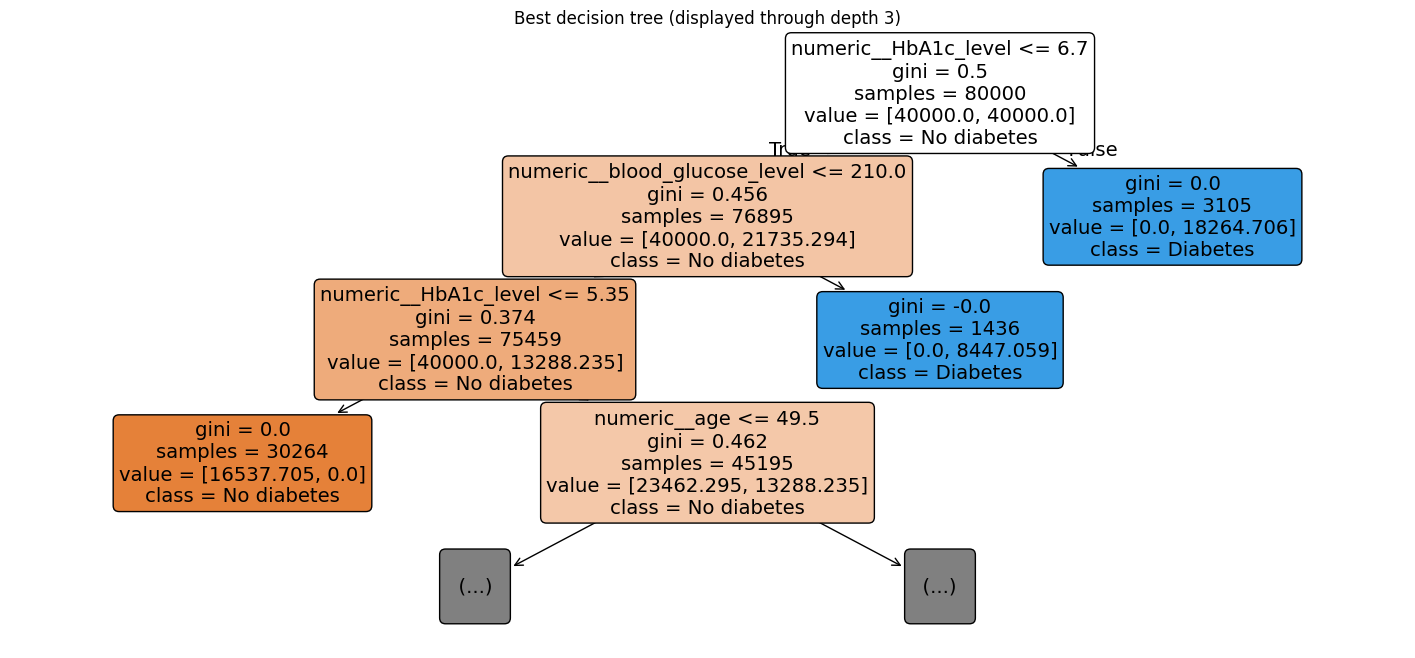

In [10]:
best_dt = cv_dt.best_estimator_
dt_test_probabilities = best_dt.predict_proba(X_test)[:, 1]
print(f"Decision-tree holdout ROC AUC: {roc_auc_score(y_test, dt_test_probabilities):.3f}")

feature_names = best_dt.named_steps["preprocessor"].get_feature_names_out()
plt.figure(figsize=(18, 8))
plot_tree(
    best_dt.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["No diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    max_depth=3,
)
plt.title("Best decision tree (displayed through depth 3)")
plt.show()

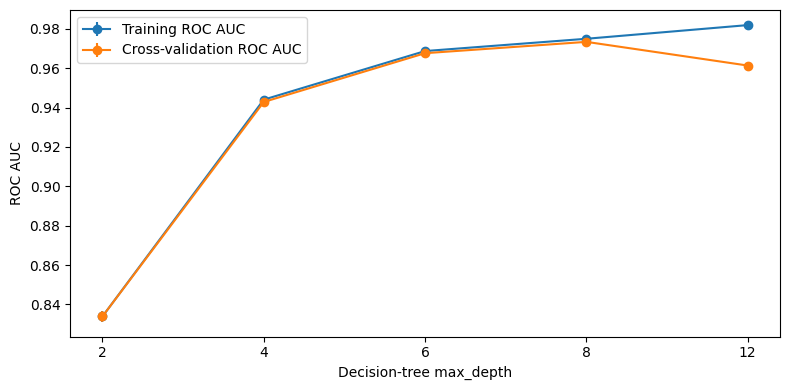

In [11]:
dt_results = pd.DataFrame(cv_dt.cv_results_)
depth_labels = [str(depth) for depth in dt_results["param_classifier__max_depth"]]
plt.figure(figsize=(8, 4))
plt.errorbar(
    depth_labels,
    dt_results["mean_train_score"],
    yerr=dt_results["std_train_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
    label="Training ROC AUC",
)
plt.errorbar(
    depth_labels,
    dt_results["mean_test_score"],
    yerr=dt_results["std_test_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
    label="Cross-validation ROC AUC",
)
plt.xlabel("Decision-tree max_depth")
plt.ylabel("ROC AUC")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced_subsample",
                random_state=42,
                n_jobs=1,
            ),
        ),
    ]
)
rf_params = {"classifier__n_estimators": [50, 100, 150]}
cv_rf_ex = GridSearchCV(
    rf_pipeline,
    param_grid=rf_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
cv_rf_ex.fit(X_train, y_train)
print("Best random-forest parameters:", cv_rf_ex.best_params_)
print(f"Best mean CV ROC AUC: {cv_rf_ex.best_score_:.3f}")

c:\Users\Chau\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best random-forest parameters: {'classifier__n_estimators': 150}
Best mean CV ROC AUC: 0.964


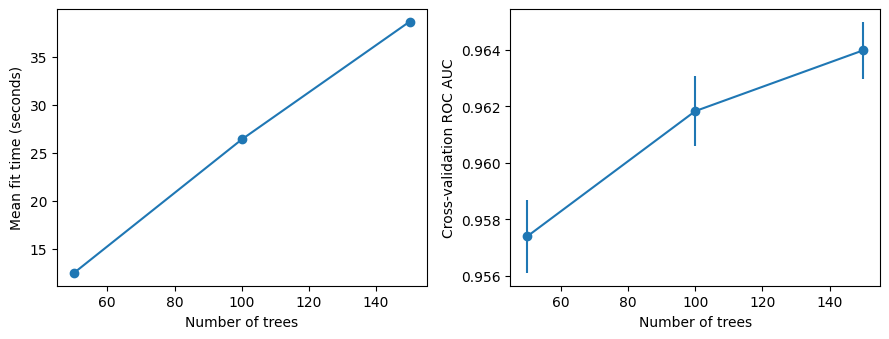

In [13]:
rf_results = pd.DataFrame(cv_rf_ex.cv_results_)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
axs[0].plot(
    rf_results["param_classifier__n_estimators"],
    rf_results["mean_fit_time"],
    "-o",
)
axs[0].set_xlabel("Number of trees")
axs[0].set_ylabel("Mean fit time (seconds)")
axs[1].errorbar(
    rf_results["param_classifier__n_estimators"],
    rf_results["mean_test_score"],
    yerr=rf_results["std_test_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
)
axs[1].set_xlabel("Number of trees")
axs[1].set_ylabel("Cross-validation ROC AUC")
plt.tight_layout()
plt.show()

Best random-forest parameters: {'classifier__n_estimators': 150}
Random-forest holdout ROC AUC: 0.964
Holdout classification report:
              precision    recall  f1-score   support

 No diabetes       0.97      0.99      0.98     18300
    Diabetes       0.93      0.70      0.79      1700

    accuracy                           0.97     20000
   macro avg       0.95      0.85      0.89     20000
weighted avg       0.97      0.97      0.97     20000



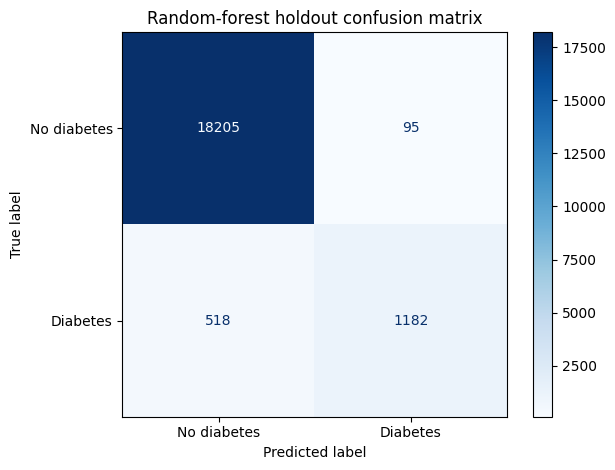

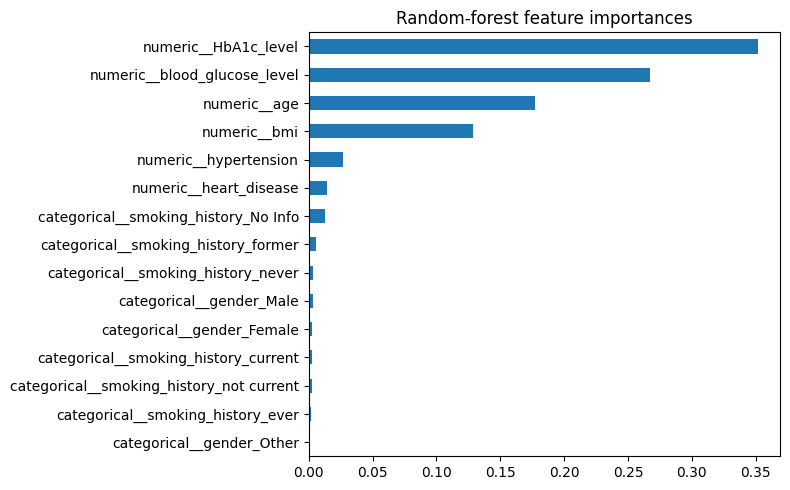

In [14]:
best_rf = cv_rf_ex.best_estimator_
rf_test_probabilities = best_rf.predict_proba(X_test)[:, 1]
rf_test_predictions = (rf_test_probabilities >= 0.5).astype(int)
print("Best random-forest parameters:", cv_rf_ex.best_params_)
print(f"Random-forest holdout ROC AUC: {roc_auc_score(y_test, rf_test_probabilities):.3f}")
print("Holdout classification report:")
print(classification_report(y_test, rf_test_predictions, target_names=["No diabetes", "Diabetes"]))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_predictions,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues",
)
plt.title("Random-forest holdout confusion matrix")
plt.tight_layout()
plt.show()

feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
feature_importances = pd.Series(
    best_rf.named_steps["classifier"].feature_importances_,
    index=feature_names,
    name="Importance",
).sort_values()
feature_importances.plot.barh(figsize=(8, 5))
plt.title("Random-forest feature importances")
plt.tight_layout()
plt.show()